In [1]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
%matplotlib inline

In [2]:
recordname = "data/apnea-ecg-database-1.0.0/c01"
record = wfdb.rdsamp(recordname)
print(record)

(array([[-0.015],
       [-0.035],
       [-0.04 ],
       ...,
       [ 0.   ],
       [ 0.   ],
       [ 0.   ]], shape=(2899000, 1)), {'fs': 100, 'sig_len': 2899000, 'n_sig': 1, 'base_date': None, 'base_time': None, 'units': ['mV'], 'sig_name': ['ECG'], 'comments': []})


In [3]:
record_small = wfdb.rdsamp(recordname, sampto = 6000)
annotation_small = wfdb.rdann(recordname, extension="apn", sampto = 6000)
print(record_small[0])

[[-0.015]
 [-0.035]
 [-0.04 ]
 ...
 [-0.02 ]
 [-0.04 ]
 [-0.04 ]]


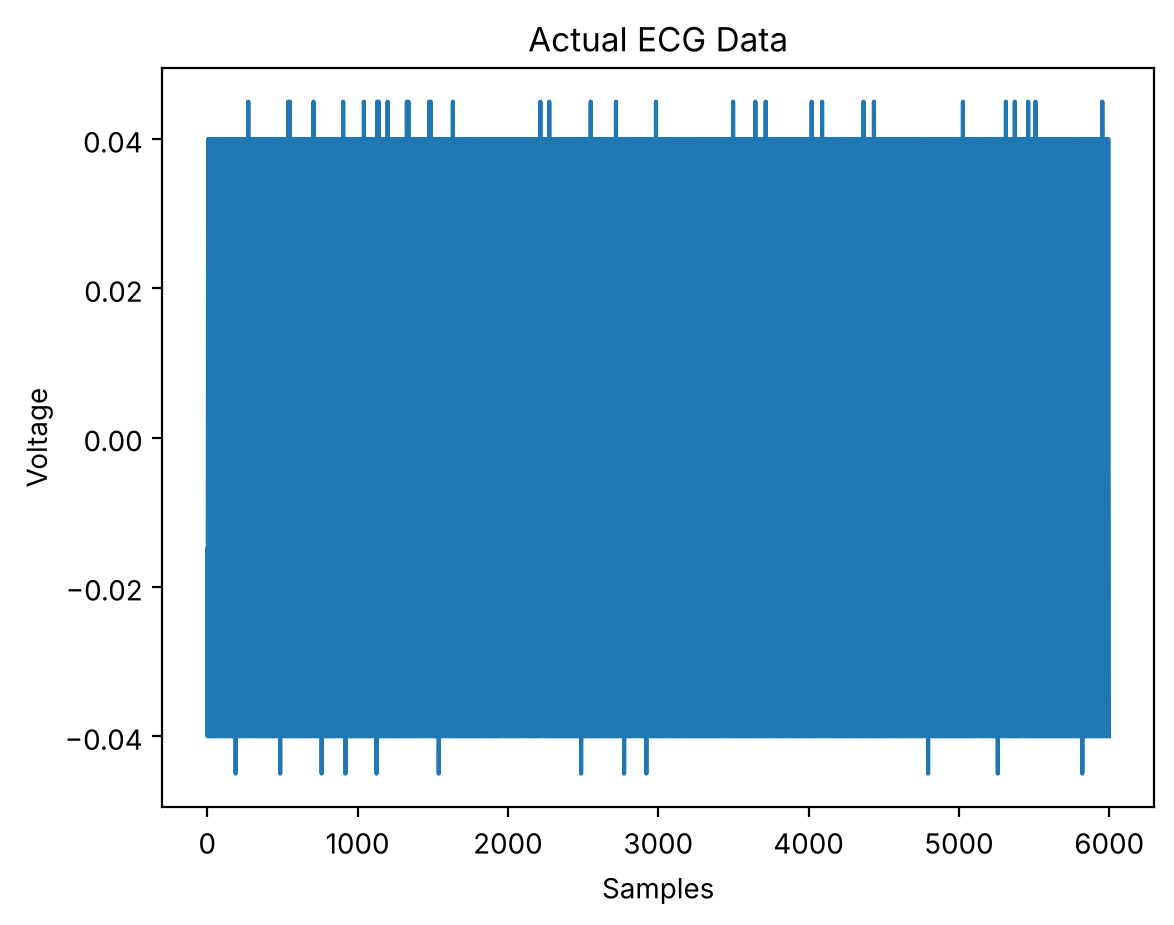

In [4]:
plt.plot(record_small[0])
plt.title('Actual ECG Data')
plt.xlabel('Samples')
plt.ylabel('Voltage')
plt.show()

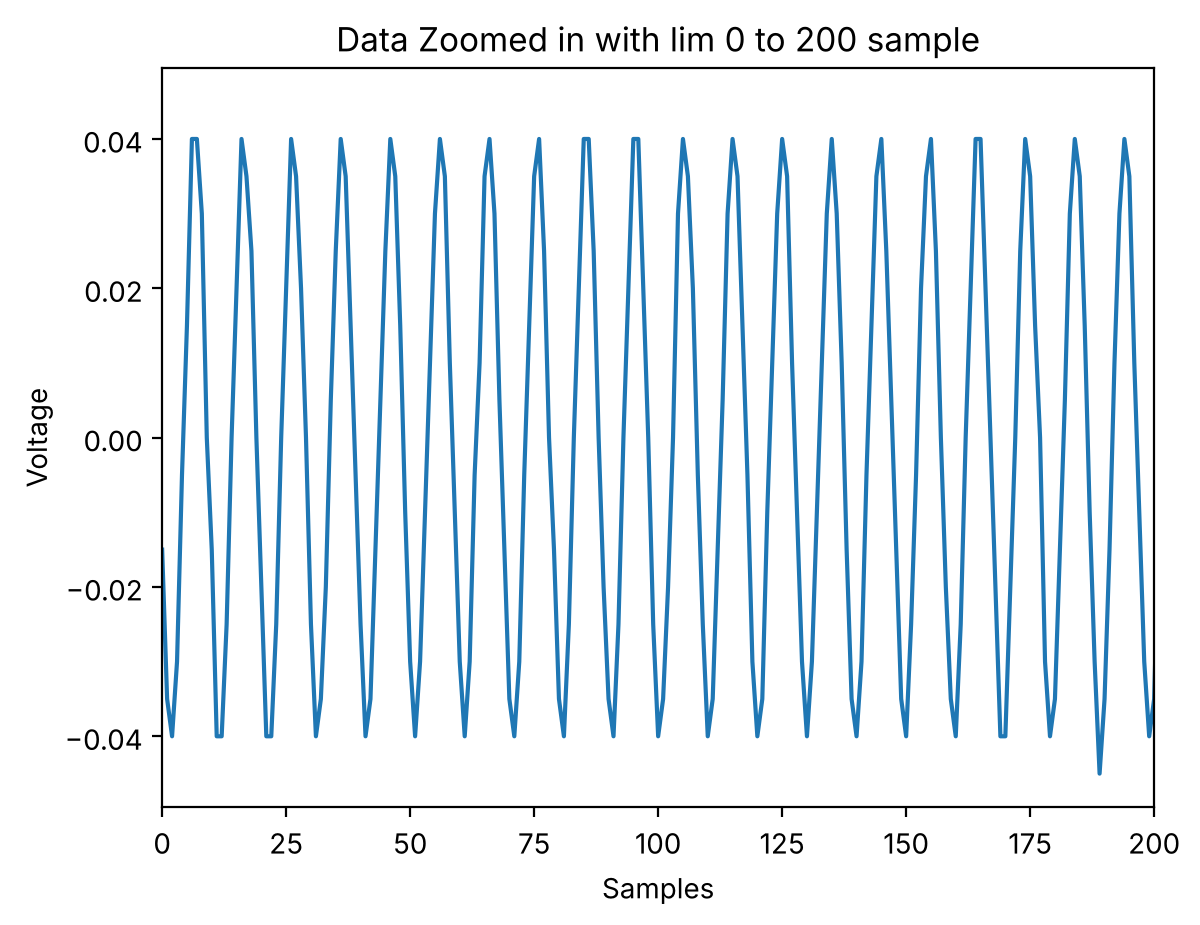

In [5]:
plt.plot(record_small[0])
plt.xlim(0, 200)
plt.title('Data Zoomed in with lim 0 to 200 sample')
plt.xlabel('Samples')
plt.ylabel('Voltage')
plt.show()


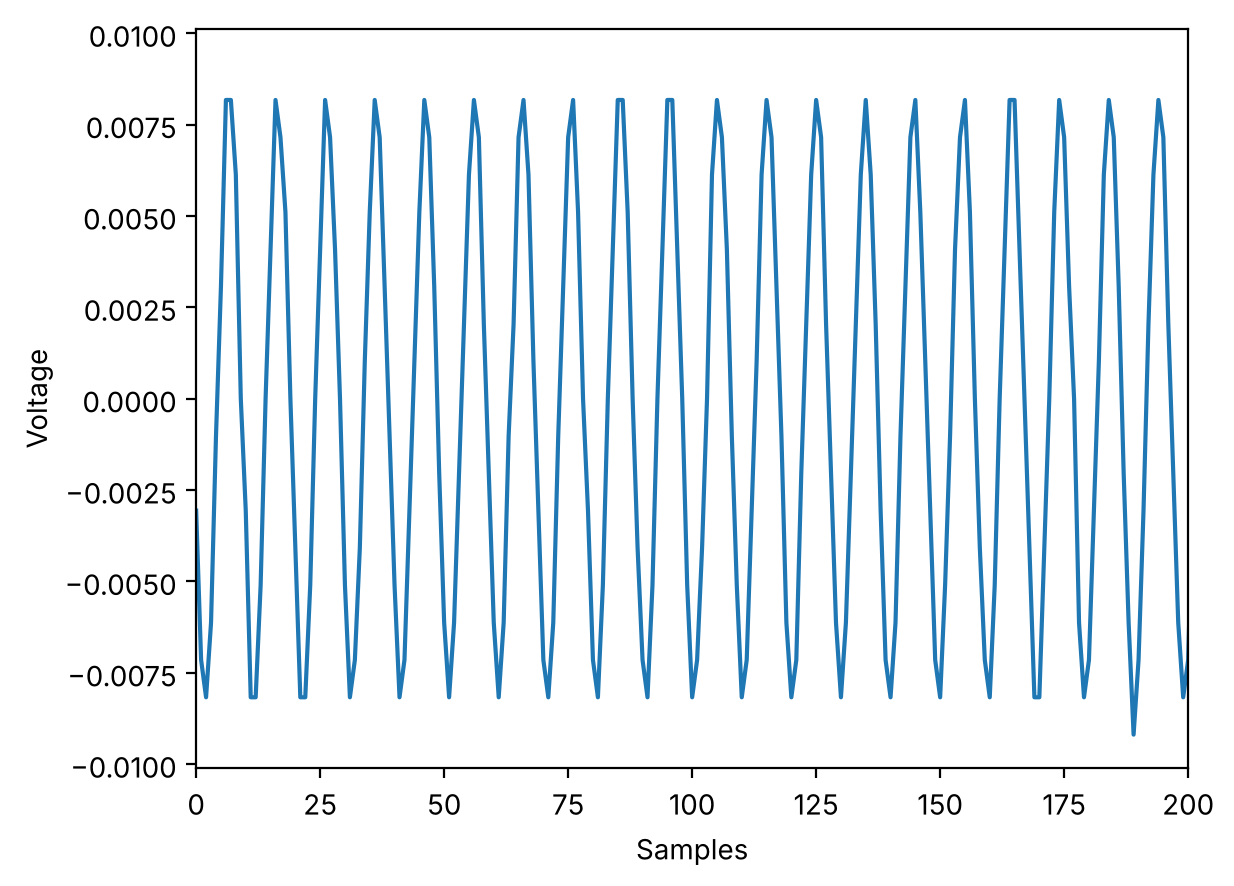

In [6]:

fs=100
unfiltered_ecg=record_small[0]
f1 = 8/fs
f2 = 16/fs
b, a = signal.butter(1, [f1*2, f2*2], btype='bandpass')
filtered_ecg = signal.lfilter(b, a, unfiltered_ecg)
plt.plot(filtered_ecg)
plt.xlim(0, 200)
plt.xlabel('Samples')
plt.ylabel('Voltage')
plt.show()

In [7]:
data=np.ravel(filtered_ecg)
data

array([-0.00306451, -0.00715053, -0.00817203, ..., -0.00408602,
       -0.00817203, -0.00817203], shape=(6000,))

In [8]:
box = np.ones(5)/5
y_smooth = np.convolve(data, box, mode='same')
y_smooth


array([-0.00367741, -0.00490322, -0.00510752, ..., -0.00306451,
       -0.00408602, -0.00408602], shape=(6000,))

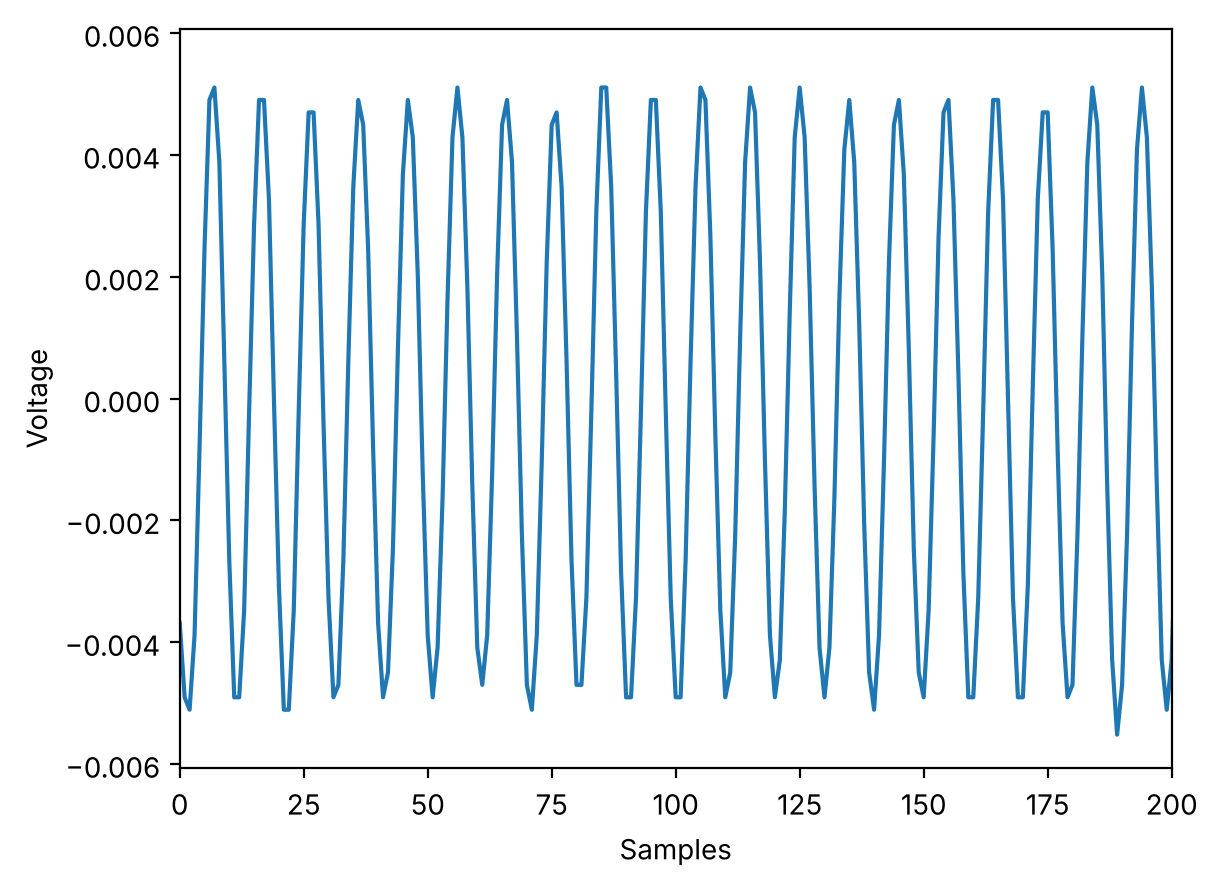

In [9]:
plt.plot(y_smooth)
plt.xlim(0, 200)
plt.xlabel('Samples')
plt.ylabel('Voltage')
plt.show()

In [10]:


plt.rcParams["figure.figsize"] = [7.50, 3.50]
plt.rcParams["figure.autolayout"] = True

class CrClass(object):
    def __init__(self, ax, x, y):
        self.ax = ax
        self.ly = ax.axvline(color='yellow', alpha=0.5)
        self.marker, = ax.plot([0], [0], marker="o", color="red", zorder=3)
        self.x = x
        self.y = y
        self.txt = ax.text(0.7, 0.9, '')

def event(self, event):
    if event.inaxes:
        x, y = event.xdata, event.ydata
        indx = np.searchsorted(self.x, [x])[0]
        x = self.x[indx]
        y = self.y[indx]
        self.ly.set_xdata(x)
        self.marker.set_data([x], [y])
        self.txt.set_text('x=%1.2f, y=%1.2f' % (x, y))
        self.txt.set_position((x, y))
        self.ax.figure.canvas.draw_idle()
    else:
        return

In [11]:
ma=filtered_ecg
n_pks = []
n_pks_ave = 0.0
s_pks = []
s_pks_ave = 0.0
QRS = [0]
RR = []
RR_ave = 0.0

th = max(ma)*0.25
print(th)
i=0
idx = []
peaks = []  
ma=y_smooth
for i in range(len(ma)):
    if i>0 and i<len(ma)-1:
        if ma[i-1]<ma[i] and ma[i+1]<ma[i]:
            peak = i
            peaks.append(i)

            if ma[peak] > th and (peak-QRS[-1])>0.3*fs:        
                QRS.append(peak)
                idx.append(i)
                s_pks.append(ma[peak])
                if len(n_pks)>8:
                    s_pks.pop(0)
                s_pks_ave = np.mean(s_pks)

                if RR_ave != 0.0:
                    if QRS[-1]-QRS[-2] > 1.5*RR_ave:
                        missed_peaks = peaks[idx[-2]+1:idx[-1]]
                        for missed_peak in missed_peaks:
                            if missed_peak-peaks[idx[-2]]>int(0.360*fs) and ma[missed_peak]>0.5*th:
                                QRS.append(missed_peak)
                                QRS.sort()
                                break

                if len(QRS)>2:
                    RR.append(QRS[-1]-QRS[-2])
                    if len(RR)>8:
                        RR.pop(0)
                    RR_ave = int(np.mean(RR))

            else:
                n_pks.append(ma[peak])
                if len(n_pks)>8:
                    n_pks.pop(0)
                n_pks_ave = np.mean(n_pks)

            th = n_pks_ave + 0.45*(s_pks_ave-n_pks_ave)

            i+=1

QRS.pop(0)

 


[0.00229838]


0

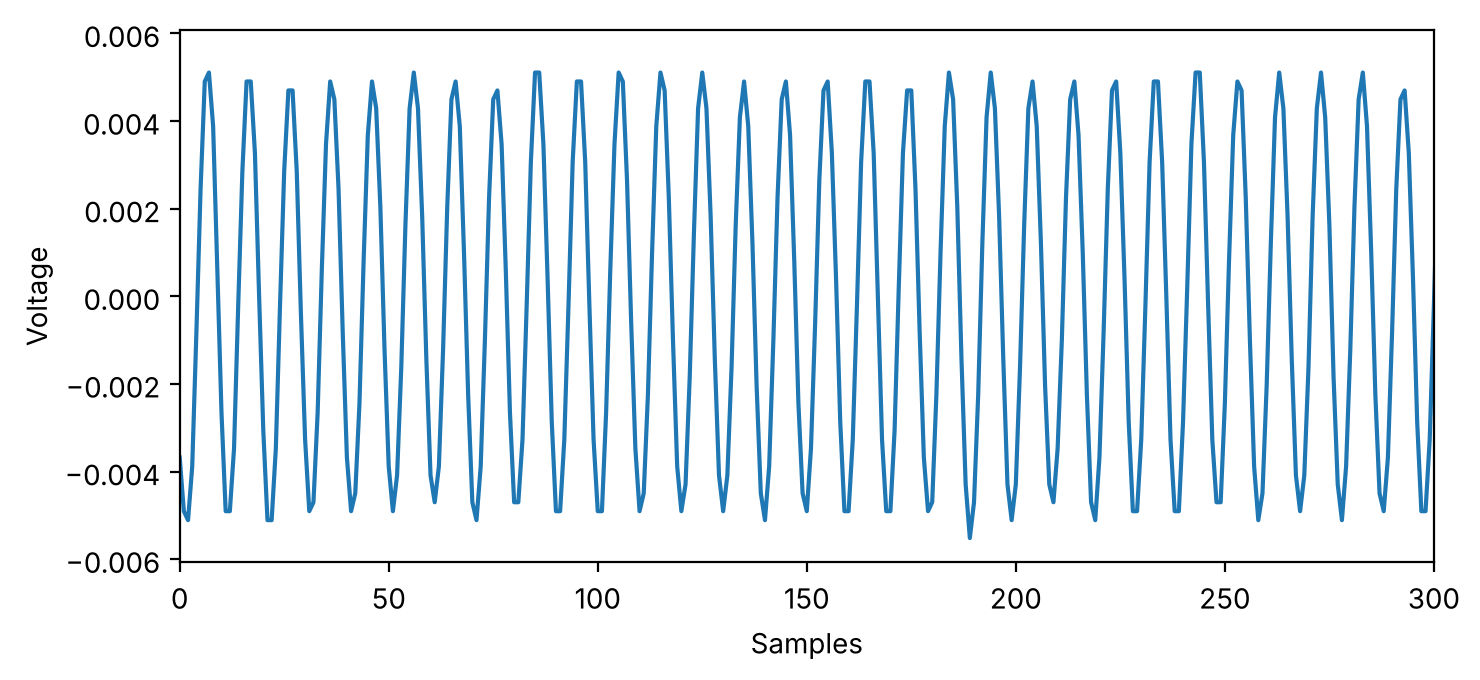

In [12]:
plt.plot(y_smooth)
plt.xlim(0, 300)
plt.xlabel('Samples')
plt.ylabel('Voltage')
plt.show()

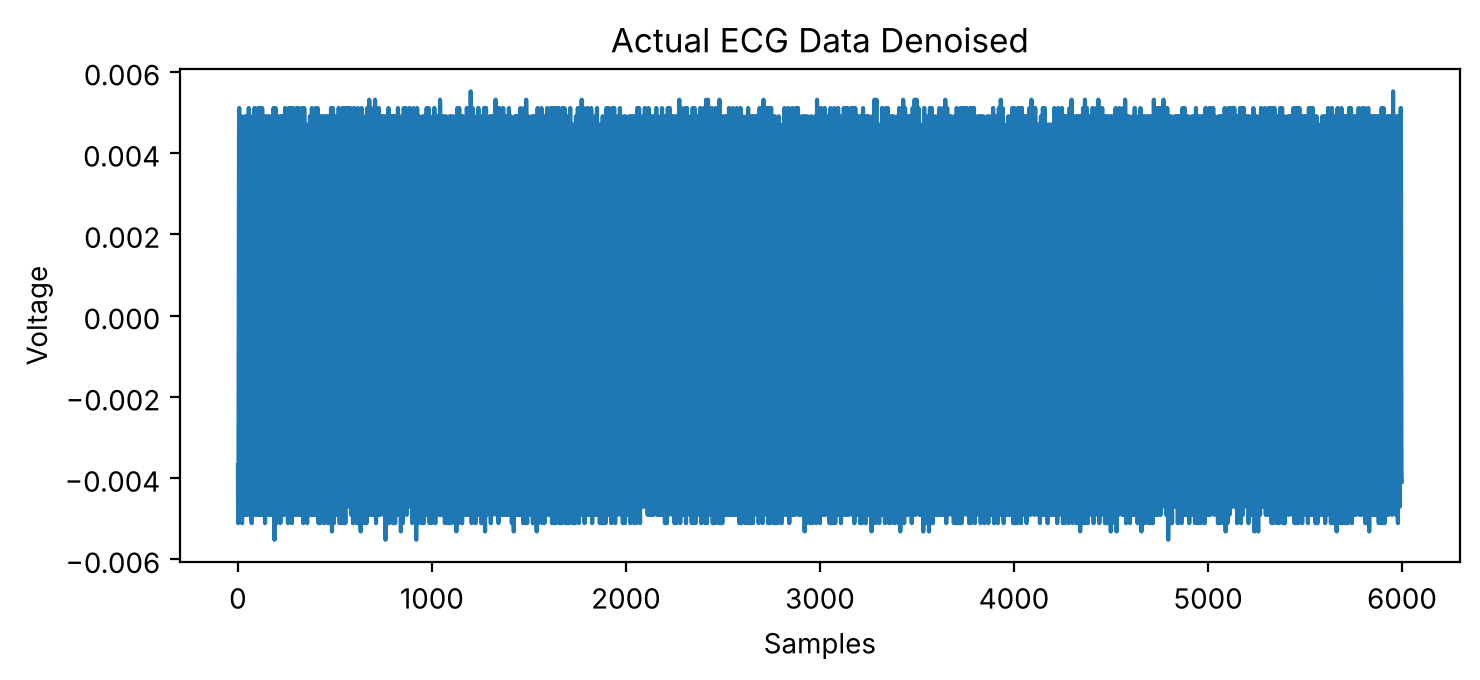

In [13]:
plt.plot(y_smooth)
plt.title('Actual ECG Data Denoised')
plt.xlabel('Samples')
plt.ylabel('Voltage')
plt.show()

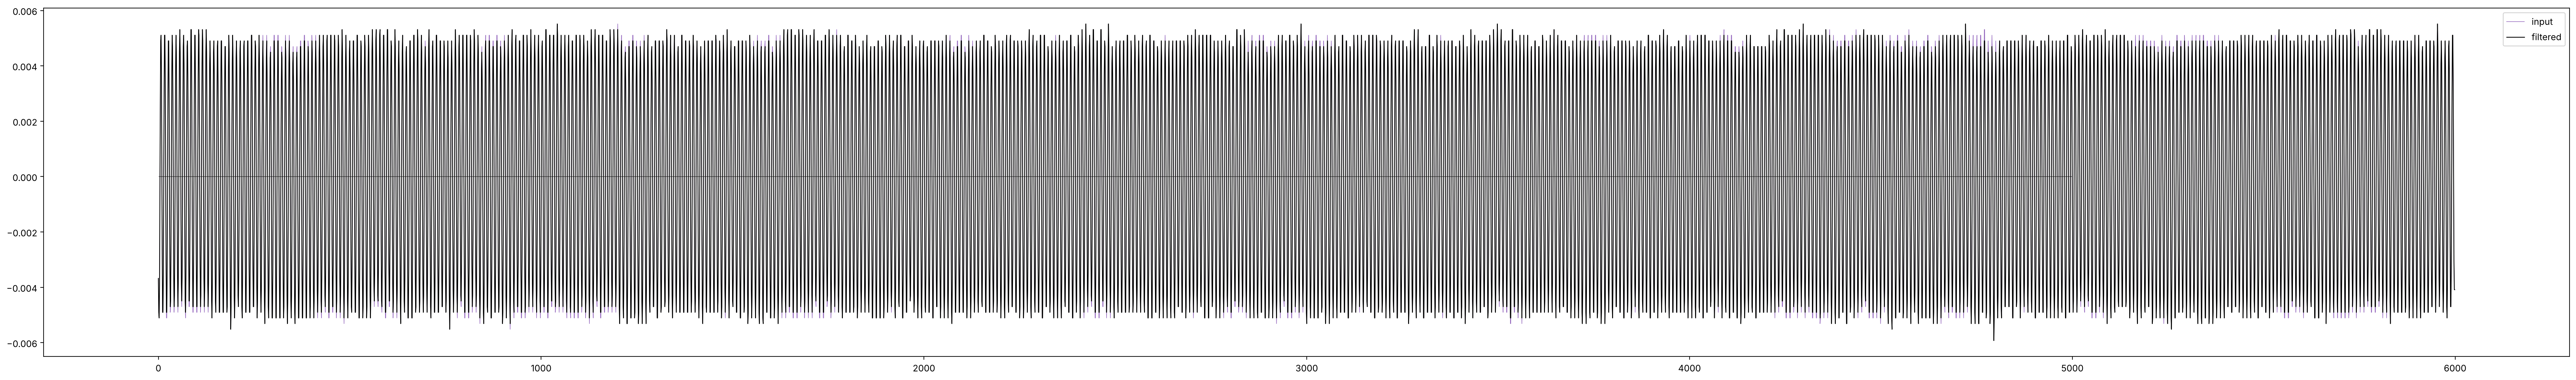

In [14]:
from scipy.signal import medfilt
BASIC_SRATE=100
def get_median_filter_width(sampling_rate, duration):
    res = int( sampling_rate*duration )
    res += ((res%2) - 1) # needs to be an odd number
    return res

ms_flt_array = [0.2,0.6]    #<-- length of baseline fitting filters (in seconds)
mfa = np.zeros(len(ms_flt_array), dtype='int')
for i in range(0, len(ms_flt_array)):
    mfa[i] = get_median_filter_width(BASIC_SRATE,ms_flt_array[i])

def filter_signal(X):
    global mfa
    X0 = X  #read orignal signal
    for mi in range(0,len(mfa)):
        X0 = medfilt(X0,mfa[mi]) # apply median filter one by one on top of each other
    X0 = np.subtract(X,X0)  # finally subtract from orignal signal
    return X0



signal_flt = filter_signal(y_smooth)
plt.figure(figsize=(40,6))

plt.plot(y_smooth, color='tab:purple', linewidth=0.6,label = 'input')
plt.plot(signal_flt, color='black', linewidth=0.9,label = 'filtered')
plt.hlines(0,0,5000,color='black', linewidth=0.4)
plt.legend()
plt.show()

 

In [15]:
i=0
idx = []
peak_value=[]
peak_index=[]
ma=y_smooth
th=np.max(ma)*0.30
print(th)
for i in range(len(ma)):
    if i>0 and i<len(ma)-1:
        if ma[i]>ma[i-1] and ma[i]>ma[i+1] and ma[i]>th:
            peak_index.append(i)
            peak_value.append(ma[i])

            
t=[x / fs for x in peak_index]
print("Index of QRS \n",peak_index)
print("\nValue of Peaks\n",peak_value)
print("\nIndex of QRS in time \n",t)
 

t_diff= [t[i+1]-t[i] for i in range(len(t)-1)]
 

0.0016548366768321422
Index of QRS 
 [7, 36, 46, 56, 66, 76, 105, 115, 125, 135, 145, 155, 184, 194, 204, 214, 224, 253, 263, 273, 283, 293, 322, 332, 342, 352, 362, 391, 401, 411, 421, 431, 441, 460, 470, 480, 490, 500, 529, 539, 549, 559, 569, 579, 608, 618, 628, 638, 648, 677, 687, 697, 707, 717, 746, 756, 766, 776, 786, 815, 825, 835, 845, 855, 894, 904, 914, 924, 934, 963, 973, 983, 993, 1003, 1042, 1052, 1062, 1072, 1101, 1111, 1121, 1131, 1141, 1180, 1190, 1200, 1210, 1220, 1249, 1259, 1269, 1279, 1289, 1318, 1328, 1338, 1348, 1358, 1387, 1397, 1407, 1417, 1427, 1456, 1466, 1476, 1486, 1496, 1535, 1545, 1555, 1565, 1575, 1585, 1604, 1614, 1624, 1634, 1644, 1673, 1683, 1693, 1703, 1713, 1752, 1762, 1772, 1782, 1792, 1821, 1831, 1841, 1851, 1861, 1890, 1900, 1910, 1920, 1930, 1969, 1979, 1989, 1999, 2009, 2038, 2048, 2058, 2068, 2078, 2107, 2117, 2127, 2137, 2147, 2176, 2186, 2196, 2206, 2216, 2226, 2245, 2255, 2265, 2275, 2285, 2295, 2324, 2334, 2344, 2354, 2364, 2393, 2403, 2413

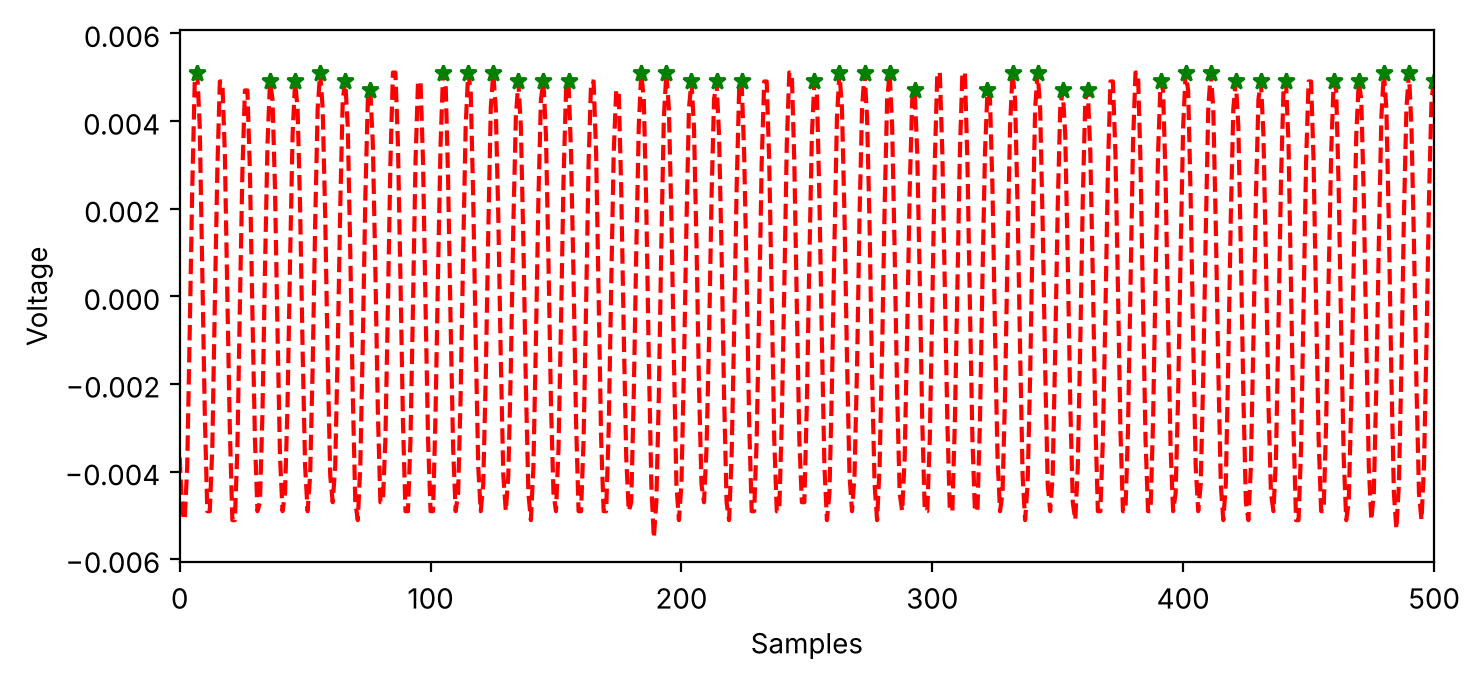

In [16]:
 
plt.plot(ma,'r--',peak_index,peak_value,'*g')
plt.xlim(0, 500)
plt.xlabel('Samples')
plt.ylabel('Voltage')
plt.show()

In [17]:
rr_intervals = t
rr_std = np.std(rr_intervals)
succ_diffs = np.asarray(t_diff)*np.asarray(t_diff)
rms = np.sqrt(np.mean(succ_diffs))
SDSD=np.std(np.asarray(t_diff))
over_50 = np.where(abs(succ_diffs)>50)
over_50 = over_50[0]
NN50=len(over_50)

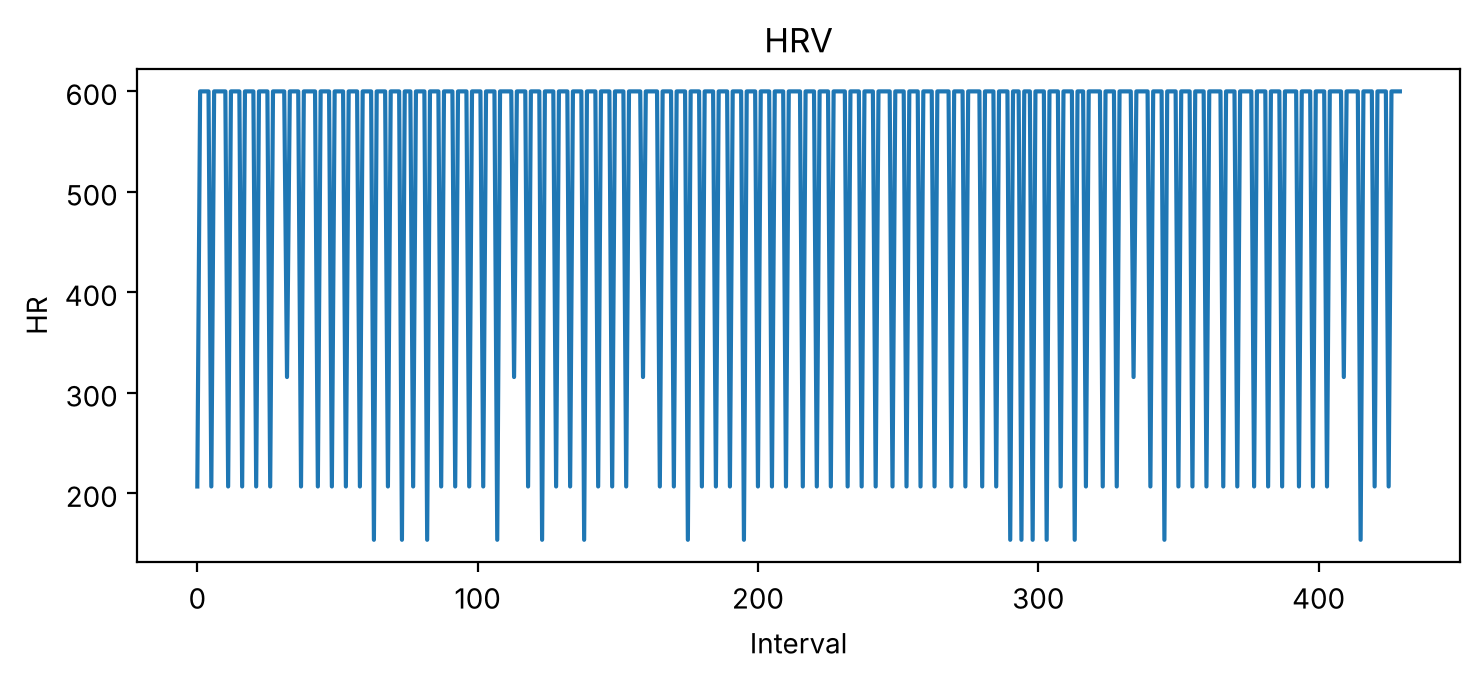


 Mean HRV 
 432

 SDNN 
 17.37917708472858

 RMSSD 
 0.16160747737708805

 NN50 
 0

 SDSD 
 0.0824377143314031


In [18]:
interval=np.arange(len(t_diff))
tp=[60 / x for x in t_diff]
plt.plot(interval,np.transpose(tp))
plt.xlabel('Interval')
plt.ylabel('HR')
plt.title('HRV')
plt.show()
print("\n Mean HRV \n",int(np.round(60/np.mean(t_diff),0)))
print("\n SDNN \n",rr_std)
print("\n RMSSD \n",rms)
print("\n NN50 \n",NN50)
print("\n SDSD \n",SDSD)